# llama.cpp — CPU/GPU Offloading, GGUF Quantization & Inference Benchmark

This Hands-on experiment extending the original notebook with CPU/GPU layer placement, optional GGUF quantization, and reproducible measurements of **generated tokens/s, latency, peak host RSS and GPU memory**.

**Environment:** Linux / Google Colab (NVIDIA GPU optional). Requires a **legally accessible GGUF model file**; supply a local path or direct download URL. No performance numbers are fabricated: execute the cells to obtain results. The results are hardware-, model- and prompt-dependent.

**Measurement caveats:** llama.cpp reports prompt evaluation and token generation separately; token/s here measures *decode* from llama.cpp timings. Wall-clock latency includes process startup/model load. Peak RSS is sampled and is not total system RAM. GPU memory is sampled via `nvidia-smi` and may include other processes; baseline is subtracted for an approximate incremental allocation. Quantization from F16/BF16 GGUF requires a compatible input model and may degrade quality.

In [1]:
from pathlib import Path
import os, sys, subprocess, shutil, re, time, json, csv, statistics, threading
from datetime import datetime, timezone

ROOT = Path.cwd()
REPO = ROOT / 'llama.cpp'
RESULTS = ROOT / 'llama_benchmark_results'
RESULTS.mkdir(exist_ok=True)
print('Working directory:', ROOT)
print('NVIDIA GPU detected:', shutil.which('nvidia-smi') is not None)
if shutil.which('nvidia-smi'):
    subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'], check=False)


Working directory: /content
NVIDIA GPU detected: True


## 1. Clone and build llama.cpp

Replaces the original notebook's `!cd` (which does not persist between notebook shell calls) with explicit paths. Enable CUDA only if the CUDA toolkit/compiler and a compatible NVIDIA GPU are available. On Colab, choose a GPU runtime first.

In [2]:
if not REPO.exists():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/ggml-org/llama.cpp', str(REPO)], check=True)
else:
    print('Repository already present:', REPO)
print('Commit:', subprocess.check_output(['git','-C',str(REPO),'rev-parse','--short','HEAD'], text=True).strip())


Commit: ac8e169


In [3]:
USE_CUDA = bool(shutil.which('nvcc') and shutil.which('nvidia-smi'))
print('Building with CUDA:', USE_CUDA)
# For a CPU-only build set USE_CUDA=False. Requires CMake and a C++ compiler.
build = REPO / ('build-cuda' if USE_CUDA else 'build-cpu')
subprocess.run(['cmake', '-S', str(REPO), '-B', str(build),
                '-DCMAKE_BUILD_TYPE=Release', f'-DGGML_CUDA={"ON" if USE_CUDA else "OFF"}'], check=True)
subprocess.run(['cmake', '--build', str(build), '--config', 'Release', '-j', '4'], check=True)
CLI = build / 'bin' / 'llama-cli'
QUANTIZE = build / 'bin' / 'llama-quantize'
assert CLI.exists(), f'Missing {CLI}'
print('Executable:', CLI)


Building with CUDA: True
Executable: /content/llama.cpp/build-cuda/bin/llama-cli


## 2. Configure model and prompt

Set `MODEL_PATH` to a GGUF file. Optionally provide `MODEL_URL` pointing **directly** to a downloadable GGUF file (not a model repository landing page). Choose a small model that fits your RAM/VRAM. No model is bundled with this notebook.

In [9]:
MODEL_PATH = ROOT / 'qwen2.5-0.5b-instruct-q8_0.gguf'
MODEL_URL = 'https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct-GGUF/resolve/main/qwen2.5-0.5b-instruct-q8_0.gguf'
PROMPT = 'Explain CUDA programming and heterogeneous CPU-GPU workload optimization in 5 sentences.'
N_PREDICT = 128
CPU_THREADS = min(8, os.cpu_count() or 4)
CONTEXT_SIZE = 2048
REPEATS = 3

if MODEL_URL and not MODEL_PATH.is_file():
    import urllib.request
    print(f'Baixando modelo de: {MODEL_URL}...')
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
    print('Download concluído!')

if not MODEL_PATH.is_file():
    print('ACTION REQUIRED: set MODEL_PATH to an existing GGUF or provide MODEL_URL and rerun this cell.')
else:
    print('Model:', MODEL_PATH, '| size GiB:', round(MODEL_PATH.stat().st_size / 2**30, 3))

Baixando modelo de: https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct-GGUF/resolve/main/qwen2.5-0.5b-instruct-q8_0.gguf...
Download concluído!
Model: /content/qwen2.5-0.5b-instruct-q8_0.gguf | size GiB: 0.629


## 3. Optional GGUF quantization

To **create** Q4_K_M and Q8_0 variants, supply a **source F16/BF16 GGUF** at `SOURCE_F16_GGUF` and set `RUN_QUANTIZATION=True`. Do **not** use an already-quantized model as input unless you understand the conversion constraints. The model must be compatible with the installed llama.cpp build. Alternatively provide prequantized GGUF files via `EXTRA_MODELS`.

In [5]:
RUN_QUANTIZATION = False
SOURCE_F16_GGUF = ROOT / 'model-f16.gguf'
QUANT_TYPES = ['Q4_K_M', 'Q8_0']
EXTRA_MODELS = {}

# Recria o dicionário garantindo que o modelo recém-baixado seja detectado
models = {'base': MODEL_PATH} if MODEL_PATH.is_file() else {}
for label, path in EXTRA_MODELS.items():
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    models[label] = path

if RUN_QUANTIZATION:
    if not SOURCE_F16_GGUF.is_file():
        raise FileNotFoundError(f'Provide unquantized source GGUF: {SOURCE_F16_GGUF}')
    for quant in QUANT_TYPES:
        out = RESULTS / f'{SOURCE_F16_GGUF.stem}-{quant.lower()}.gguf'
        if not out.exists():
            subprocess.run([str(QUANTIZE), str(SOURCE_F16_GGUF), str(out), quant], check=True)
        models[quant] = out

print('Models configured for the benchmark:', {k: str(v) for k, v in models.items()})

{}


## 4. Benchmark CPU vs hybrid CPU/GPU vs GPU offloading

`-ngl 0` disables layer offloading; `-ngl 8` offloads up to eight layers; `-ngl 999` requests maximum possible GPU layer offloading (subject to backend, model and VRAM). A failed run is recorded rather than silently discarded. Use **one process at a time** and keep the GPU otherwise idle.

Metrics:
- `decode_tokens_per_second`: generated-token rate from llama.cpp `eval time` / token count.
- `prompt_tokens_per_second`: prefill rate from `prompt eval time`.
- `wall_latency_s`: elapsed time from subprocess start to exit, including loading.
- `peak_host_rss_mib`: maximum sampled resident memory of the process and children (requires `psutil`).
- `peak_gpu_delta_mib`: peak total NVIDIA GPU memory use minus idle baseline, **approximate**, not per-process. A shared GPU invalidates this estimate.
- `model_size_gib`: GGUF disk size, not the runtime memory footprint.

The benchmark is sequential and uses a repeated prompt. Results include warm-cache effects; interpret carefully.

In [6]:
try:
    import psutil
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'psutil'], check=True)
    import psutil

def gpu_used_mib():
    if not shutil.which('nvidia-smi'):
        return None
    r = subprocess.run(['nvidia-smi','--query-gpu=memory.used','--format=csv,noheader,nounits'],
                       capture_output=True, text=True)
    if r.returncode != 0:
        return None
    try:
        return sum(int(x.strip()) for x in r.stdout.splitlines() if x.strip())
    except ValueError:
        return None

def timing_metrics(output):
    # llama.cpp typically prints: 'llama_perf_context_print: ... eval time = ... ms / ... runs ( ... tokens per second)'
    data = {}
    for name, prefix in [('prompt', 'prompt eval time'), ('decode', 'eval time')]:
        lines = [line for line in output.splitlines() if re.search(r'\b'+re.escape(prefix)+r'\s*=', line)]
        if lines:
            line = lines[-1]
            rate = re.search(r'([\d.]+)\s+tokens per second', line)
            ms = re.search(r'=\s*([\d.]+)\s*ms', line)
            runs = re.search(r'/\s*(\d+)\s+(?:tokens|runs)', line)
            data[f'{name}_tokens_per_second'] = float(rate.group(1)) if rate else None
            data[f'{name}_eval_ms'] = float(ms.group(1)) if ms else None
            data[f'{name}_token_count'] = int(runs.group(1)) if runs else None
    return data

def run_benchmark(model_path, label, ngl, repeat):
    cmd = [str(CLI), '-m', str(model_path), '-p', PROMPT, '-n', str(N_PREDICT),
           '-c', str(CONTEXT_SIZE), '-t', str(CPU_THREADS), '-ngl', str(ngl),
           '--no-warmup']
    baseline = gpu_used_mib()
    start = time.perf_counter()
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    process = psutil.Process(proc.pid)
    peak_rss = 0
    peak_gpu = baseline
    # communicate in a background thread to prevent output pipe deadlock
    output = {}
    def collect():
        output['stdout'], output['stderr'] = proc.communicate()
    thread = threading.Thread(target=collect, daemon=True)
    thread.start()
    while thread.is_alive():
        try:
            children = process.children(recursive=True)
            rss = sum(p.memory_info().rss for p in [process, *children] if p.is_running())
            peak_rss = max(peak_rss, rss)
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            pass
        used = gpu_used_mib()
        if used is not None:
            peak_gpu = max(peak_gpu or 0, used)
        time.sleep(0.10)
    thread.join()
    wall = time.perf_counter() - start
    combined = output.get('stdout','') + '\n' + output.get('stderr','')
    row = dict(timestamp_utc=datetime.now(timezone.utc).isoformat(), model=label,
               model_path=str(model_path), model_size_gib=round(model_path.stat().st_size/2**30, 3),
               gpu_layers_requested=ngl, repeat=repeat, returncode=proc.returncode,
               wall_latency_s=round(wall,3), peak_host_rss_mib=round(peak_rss/2**20,1),
               peak_gpu_delta_mib=(max(0,peak_gpu-baseline) if peak_gpu is not None and baseline is not None else None),
               **timing_metrics(combined))
    if proc.returncode != 0:
        row['error_tail'] = combined[-1500:]
    return row, combined


In [11]:
# Recria o dicionário de modelos caso ele esteja vazio no kernel mas o arquivo já exista no disco
if not models and 'MODEL_PATH' in globals() and MODEL_PATH.is_file():
    models = {'base': MODEL_PATH}

if not models:
    raise RuntimeError('No GGUF model configured. Complete section 2 before benchmarking.')

OFFLOAD_CONFIGS = {'CPU': 0, 'Hybrid_8_layers': 8, 'Max_GPU': 999} if USE_CUDA else {'CPU': 0}
rows = []
for model_label, model_file in models.items():
    for placement, ngl in OFFLOAD_CONFIGS.items():
        for repeat in range(1, REPEATS + 1):
            print(f'Running model={model_label} placement={placement} repeat={repeat}/{REPEATS}', flush=True)
            row, log = run_benchmark(model_file, model_label, ngl, repeat)
            row['placement'] = placement
            rows.append(row)
            (RESULTS / f'{model_label}_{placement}_{repeat}.log').write_text(log)
            print('  status:', row['returncode'], 'decode tok/s:', row.get('decode_tokens_per_second'),
                  'wall s:', row['wall_latency_s'])
            if row['returncode'] != 0:
                print('  failed:', row.get('error_tail', '')[-350:])
                break
csv_path = RESULTS / 'benchmark.csv'
keys = list(dict.fromkeys(k for row in rows for k in row))
with csv_path.open('w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=keys)
    writer.writeheader()
    writer.writerows(rows)
(RESULTS / 'benchmark.json').write_text(json.dumps(rows, indent=2))
print('Saved:', csv_path)

Running model=base placement=CPU repeat=1/3
  status: 0 decode tok/s: None wall s: 10.249
Running model=base placement=CPU repeat=2/3
  status: 0 decode tok/s: None wall s: 9.699
Running model=base placement=CPU repeat=3/3
  status: 0 decode tok/s: None wall s: 9.669
Running model=base placement=Hybrid_8_layers repeat=1/3
  status: 0 decode tok/s: None wall s: 6.328
Running model=base placement=Hybrid_8_layers repeat=2/3
  status: 0 decode tok/s: None wall s: 6.466
Running model=base placement=Hybrid_8_layers repeat=3/3
  status: 0 decode tok/s: None wall s: 6.186
Running model=base placement=Max_GPU repeat=1/3
  status: 0 decode tok/s: None wall s: 2.081
Running model=base placement=Max_GPU repeat=2/3
  status: 0 decode tok/s: None wall s: 1.908
Running model=base placement=Max_GPU repeat=3/3
  status: 0 decode tok/s: None wall s: 1.921
Saved: /content/llama_benchmark_results/benchmark.csv


## 5. Compare results and plot performance

Report medians of successful runs; failures remain visible in the raw CSV and logs. For rigorous latency studies, separately benchmark model-load time, prefill time, time to first token, and per-token decode latency. This notebook reports the first two where llama.cpp exposes them, plus total wall time.

,model,placement,decode_tokens_per_second,prompt_tokens_per_second,wall_latency_s,peak_host_rss_mib,peak_gpu_delta_mib
0,base,CPU,NaN,NaN,9.699,1038.6,163.0
1,base,Hybrid_8_layers,NaN,NaN,6.328,919.6,415.0
2,base,Max_GPU,NaN,NaN,1.921,973.1,683.0


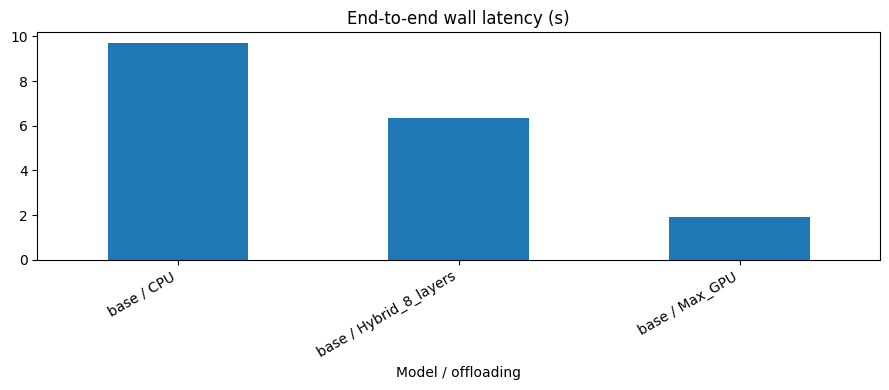

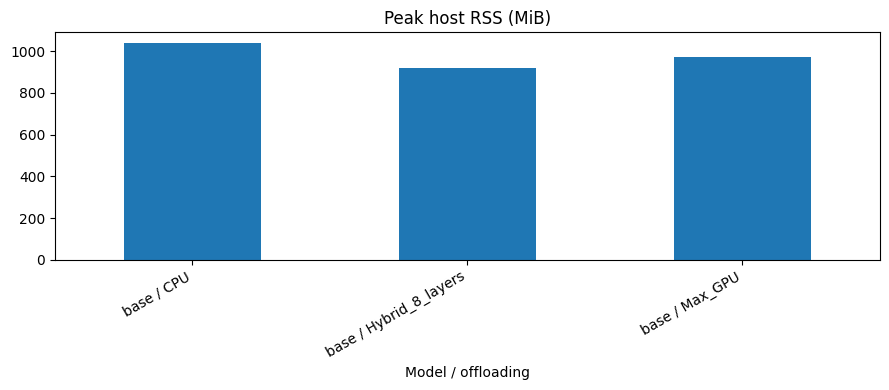

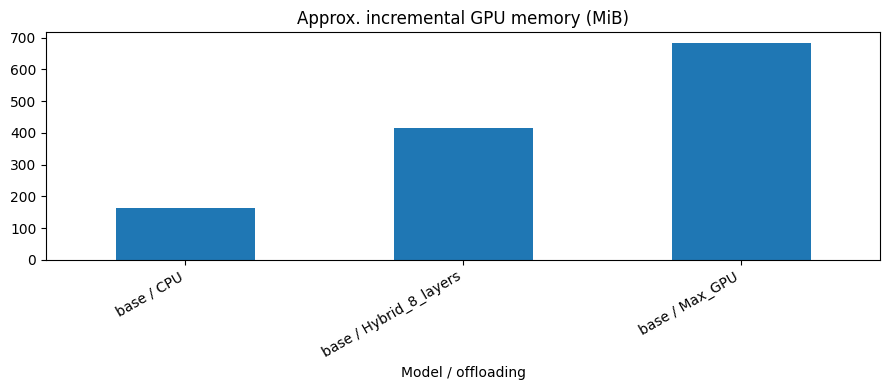

Raw data, summary and plots in: /content/llama_benchmark_results


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(rows)
ok = df[df.returncode == 0].copy()
if ok.empty:
    print('No successful runs. Inspect logs in', RESULTS)
else:
    metrics = ['decode_tokens_per_second', 'prompt_tokens_per_second', 'wall_latency_s',
               'peak_host_rss_mib', 'peak_gpu_delta_mib']
    for metric in metrics:
        if metric not in ok.columns:
            ok[metric] = float('nan')
    summary = ok.groupby(['model','placement'], as_index=False)[metrics].median(numeric_only=True)
    display(summary)
    summary.to_csv(RESULTS / 'summary.csv', index=False)
    for metric, title in [('decode_tokens_per_second','Decode throughput (tokens/s)'),
                          ('wall_latency_s','End-to-end wall latency (s)'),
                          ('peak_host_rss_mib','Peak host RSS (MiB)'),
                          ('peak_gpu_delta_mib','Approx. incremental GPU memory (MiB)')]:
        if summary[metric].notna().any():
            ax = summary.assign(config=summary['model']+' / '+summary['placement']).plot.bar(
                x='config', y=metric, legend=False, figsize=(9,4), title=title)
            ax.set_xlabel('Model / offloading'); plt.xticks(rotation=30, ha='right')
            plt.tight_layout()
            plt.savefig(RESULTS / (metric+'.png'), dpi=150)
            plt.show()
print('Raw data, summary and plots in:', RESULTS)
